In [1]:
import pandas as pd

daily_return_df = pd.read_csv('sp500_joined_daily_returns_yahoo.csv')
daily_return_df.set_index('Date', inplace=True)

windows = [5,10,20,40,60]
daily_return_df.shape

(5267, 506)

# Beta error statistics #

<AxesSubplot:xlabel='Date'>

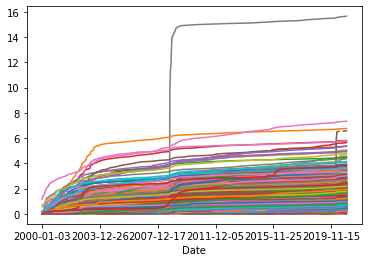

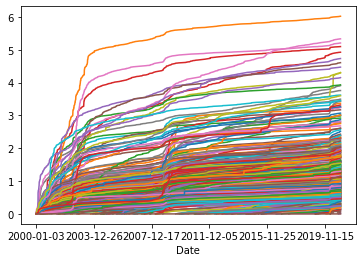

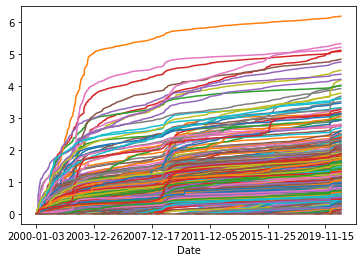

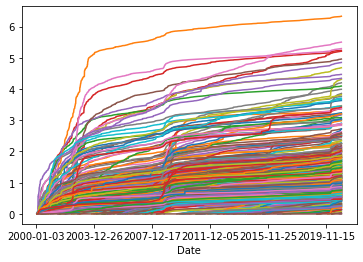

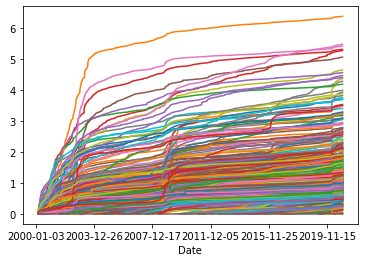

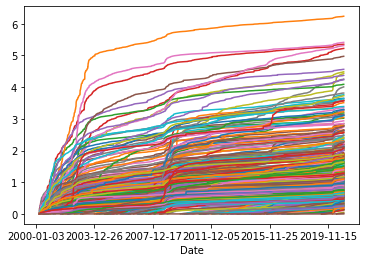

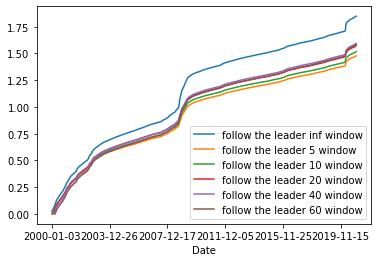

In [2]:
FTL_mean_results = pd.DataFrame()

# Infinite window
beta_df = daily_return_df.expanding().cov(daily_return_df['SPY']).div(daily_return_df['SPY'].expanding().var(), axis=0)
beta_error_df = (daily_return_df - beta_df.mul(daily_return_df['SPY'], axis=0)) ** 2
beta_error_df.cumsum().plot(legend=False)
FTL_mean_results["follow the leader inf window"] = beta_error_df.mean(axis=1).cumsum()

for window in windows:
    beta_df = daily_return_df.rolling(window).cov(daily_return_df['SPY']).div(daily_return_df['SPY'].rolling(window).var(), axis=0)
    beta_error_df = (daily_return_df - beta_df.mul(daily_return_df['SPY'], axis=0)) ** 2
    beta_error_df.cumsum().plot(legend=False)
    FTL_mean_results["follow the leader {} window".format(window)] = beta_error_df.mean(axis=1).cumsum()
FTL_mean_results.plot()


# Follow the Leader #

## With vectorization ##

In [3]:
concat = None
for w in windows:
    beta_df = daily_return_df.rolling(window=w).cov(daily_return_df['SPY']).div(daily_return_df['SPY'].rolling(window=w).var(), axis=0)
    beta_error_df = (daily_return_df - beta_df.mul(daily_return_df['SPY'].mean(), axis=0)) ** 2    
    beta_error_df.columns = beta_error_df.columns + "_{0}".format(w)
    if concat is not None:
        concat = pd.concat([concat,beta_error_df], axis=1)
    else:
        concat = beta_error_df

In [4]:
concat

,MMM_5,ABT_5,ABBV_5,ABMD_5,ACN_5,ATVI_5,ADBE_5,AMD_5,AAP_5,AES_5,...,XEL_60,XRX_60,XLNX_60,XYL_60,YUM_60,ZBRA_60,ZBH_60,ZION_60,ZTS_60,SPY_60
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-07,0.000258,0.000839,NaN,0.000012,NaN,2.477986e-04,2.675041e-03,0.002996,NaN,0.000527,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-01,0.000454,0.000046,0.000093,0.000205,8.862883e-06,2.214304e-09,3.527042e-05,0.000018,0.000559,0.000009,...,0.000136,0.000040,0.000030,2.159185e-05,0.000022,0.000616,0.000853,0.000186,0.000003,1.420622e-06
2020-12-02,0.000086,0.000002,0.000090,0.000121,1.741379e-05,4.965634e-05,1.369169e-04,0.000086,0.000325,0.001085,...,0.000053,0.000204,0.000080,9.365155e-07,0.000071,0.000090,0.000292,0.001599,0.000163,2.873947e-05
2020-12-03,0.000020,0.000032,0.000006,0.000137,6.646126e-08,4.174672e-05,1.783705e-05,0.000341,0.000103,0.000004,...,0.000215,0.000009,0.000495,7.090578e-06,0.000002,0.000140,0.000066,0.000242,0.000091,1.370599e-10


In [5]:
beta_error = pd.DataFrame()
for ticker in daily_return_df.columns:
    prefix = ticker + '_'
    head = []
    for i in range(0,len(windows)):
        head.append(prefix + str(windows[i]))
    beta_error[ticker] = concat[head].min(axis=1)

<AxesSubplot:xlabel='Date'>

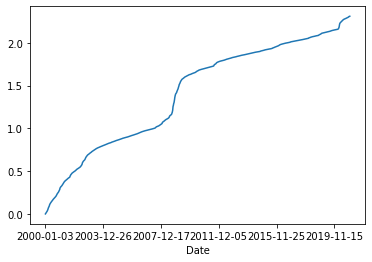

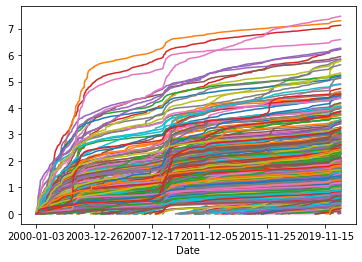

In [6]:
beta_error.mean(axis=1).cumsum().plot()
beta_error.cumsum().plot(legend=False)

## With iteration (slow) ##

In [7]:
# The code above can fully replace this one and way faster, 
# but it might be easier to understand the FTL conception with iteration.
# This also has a limited behaviour, we would run over the tickers too
# to calcluate different windows for them, but it would run up to a day.

market_variance = {\
    5: daily_return_df['SPY'].rolling(window=5).var(),\
    10: daily_return_df['SPY'].rolling(window=10).var(),\
    20: daily_return_df['SPY'].rolling(window=20).var(),\
    40: daily_return_df['SPY'].rolling(window=40).var(),\
    60: daily_return_df['SPY'].rolling(window=60).var()}

FTL_betas = pd.DataFrame().reindex(columns = daily_return_df.columns)
FTL_beta_error = pd.DataFrame().reindex(columns = daily_return_df.columns)
W = pd.DataFrame(0.0,index=windows, columns=['error'])
cumsum = pd.DataFrame(0.0, index=["beta error"], columns=daily_return_df.columns)

indexes = {}
for i in range(0,21):
    index = [idx for idx, s in enumerate(daily_return_df.index) if '20'+f"{i:02d}" in s]
    indexes[i] = [index[0],index[-1]]

for year in range(21):
    print('20'+f"{year:02d}")
    min_window = W.idxmin()['error']
    start_index = indexes[year][0]
    end_index = indexes[year][1]
    
    variance = market_variance[min_window][start_index:end_index]
    daily = daily_return_df[start_index : end_index]
    spy = daily_return_df['SPY'][start_index:end_index]
    act_beta = daily.rolling(window=min_window).cov(spy).div(variance, axis=0)
    FTL_betas = FTL_betas.append(act_beta)

    # refresh weights
    act_beta_error = (daily - act_beta.mul(spy.mean(), axis=0)) ** 2
    FTL_beta_error = FTL_beta_error.append(act_beta_error)
    W['error'][min_window] += act_beta_error.mean().sum() / 1000.0
    for window in windows:
        if window == min_window:
            continue
        variance = market_variance[window][start_index:end_index]
        beta = daily.rolling(window=window).cov(spy).div(variance, axis=0)
        beta_error = (daily - beta.mul(spy.mean(), axis=0)) ** 2
        W['error'][window] += beta_error.mean().sum() / 1000.0

2000
2001
2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
